# **The ISA book**



This notebook concerns the (current) final book of the ISA automatic trading system, that being the combination each other part, alongside comparing portfolio optimisation techniques across the book.

## Imports

In [1]:
import sys
from pathlib import Path

here = Path.cwd()
src = next(c for p in [here, *here.parents]
           for c in (p / "src", p / "isa_showcase" / "src", p / "isa_portfolio" / "isa_showcase" / "src",
                     p / "trading_portfolio" / "isa_portfolio" / "isa_showcase" / "src")
           if (c / "showcase_plots.py").exists())
sys.path.insert(0, str(src))
import pandas as pd
import showcase_plots as sp
sp.style()
d = sp.monthly()

## The book vs Major indices

The main aim of this system was to outperform standard investing methods, i.e buy-and-hold a major stock index. By 'outperform', that is by Sharpe, total final equity, and hopefully max drawdown. This was completed, and is show on the plot below. This is not a perfect benchmark, but just a showcase of the system against what it was hoped to beat.

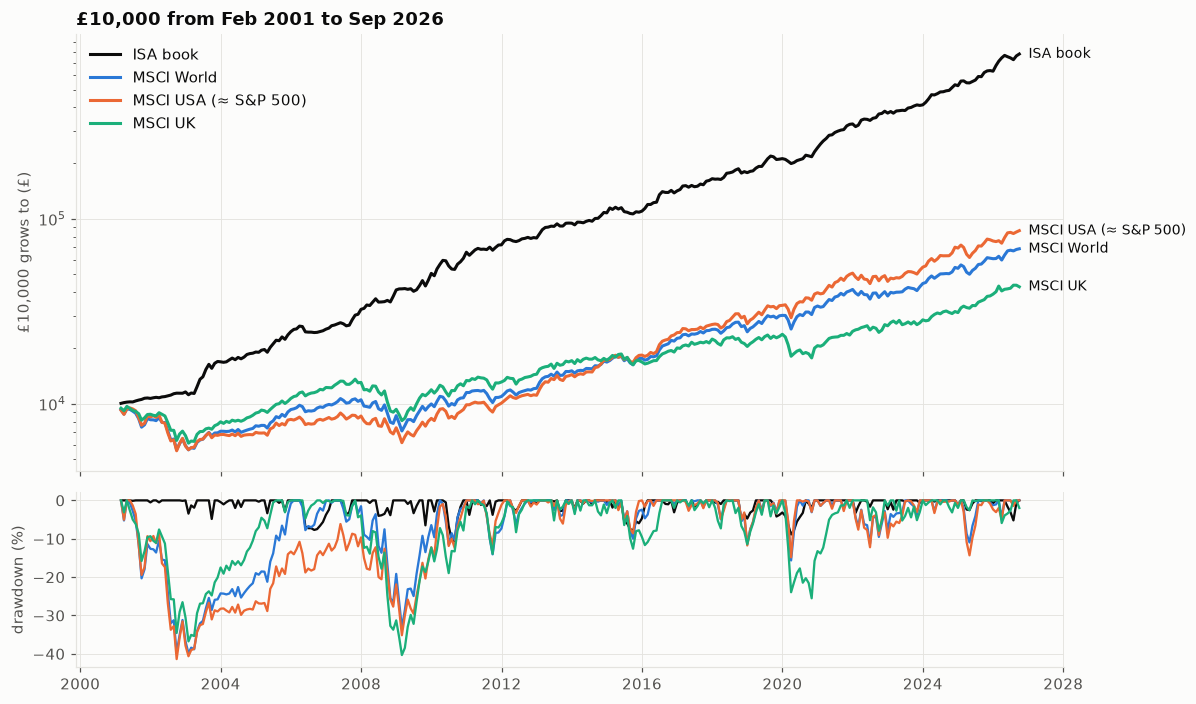

,CAGR %,Sharpe,volatility %,max drawdown %,£10k becomes
ISA book,18.490,1.530,9.910,-10.640,"778,620.830"
MSCI World,7.810,0.450,13.660,-39.910,"68,864.430"
MSCI USA (≈ S&P 500),8.760,0.490,14.360,-41.370,"86,302.890"
MSCI UK,5.840,0.320,13.150,-40.310,"42,887.750"


In [2]:
b = sp.table("benchmarks_monthly.csv").set_index("month")
b.index = pd.PeriodIndex(b.index, freq="M").to_timestamp("M")
series = {"ISA book": d["book"],
          "MSCI World": b["MSCI World"].reindex(d.index),
          "MSCI USA (≈ S&P 500)": b["MSCI USA"].reindex(d.index),
          "MSCI UK": b["MSCI UK"].reindex(d.index)}
colors = {"ISA book": sp.COLORS["book"], "MSCI World": "#2a78d6", "MSCI USA (≈ S&P 500)": "#eb6834", "MSCI UK": "#1baf7a"}
sp.curves(series, colors, f"£10,000 from {d.index[0]:%b %Y} to {d.index[-1]:%b %Y}")

def summary(r):
    x = r - d["cash"]
    w = (1 + r).cumprod()
    return pd.Series({"CAGR %": 100 * (w.iloc[-1] ** (12 / len(r)) - 1),
                      "Sharpe": x.mean() / x.std() * 12 ** 0.5,
                      "volatility %": 100 * r.std() * 12 ** 0.5,
                      "max drawdown %": (100 * (w / w.cummax() - 1)).min(),
                      "£10k becomes": 10_000 * w.iloc[-1]})

pd.DataFrame({k: summary(v) for k, v in series.items()}).T.round(2)

The statistics align with the plot, that the book does infact outperform these 3 major stock indices.

## Building the book part by part

The book is a combination of the 5 other folders in the showcase, that being a core holding, a defensive basket for tough economic periods, a rebound basket held just after such tough economic period alongside 'sleeves' and 'overlays' which contain assets which are held under certain market conditions and timings. The following table shows how each component adds to the final product

In [3]:
t = sp.table("layers_stats.csv")
t = t[t["window"].str.startswith("full")].set_index("layers")
t[["cagr_pct", "sharpe", "max_drawdown_pct", "final_gbp_from_10k"]].round(2)

,cagr_pct,sharpe,max_drawdown_pct,final_gbp_from_10k
layers,,,,
core,8.620,0.550,-35.690,"83,518.240"
core + defensive,10.650,0.840,-16.120,"134,343.440"
core + defensive + rebound,13.750,0.950,-20.470,"273,062.350"
core + defensive + rebound + overlay,14.830,1.030,-20.470,"347,619.290"
book (all five parts),18.490,1.530,-10.640,"778,620.830"


## Each part's contribution

The below table shows how much each part contributes to the portfolio.

In [4]:
t = sp.table("parts_stats.csv")
t = t[t["window"].str.startswith("full")].set_index("part")
t[["mean_pp_per_year", "vol_pp_per_year", "sharpe_of_contribution", "correlation_with_core"]].round(2)

,mean_pp_per_year,vol_pp_per_year,sharpe_of_contribution,correlation_with_core
part,,,,
core,9.010,11.940,0.750,1.000
defensive,1.640,7.300,0.220,-0.560
rebound,3.000,5.100,0.590,0.150
overlay,0.950,1.940,0.490,-0.090
sleeves,2.970,7.260,0.410,-0.320


See that (unsurprisingly) the core and sleeves, alongside the rebound basket are the biggest contributors to the book. The biggest thing to note here is that each basket is uncorrelated with the core, leading to a wide range of diverse return sources, which is something I was really keen for.

## Weighting methods: the shipped configuration

I now compared a variety of known portfolio optimisation techniques to the book. It is key to note that these were applied to each sleeve and overlay individually, not cumalitively.

In [5]:
t = sp.table("methods_shipped_config.csv").head(6).set_index("method_name")
t[["floor", "cap", "sharpe", "cagr_pct", "max_drawdown_pct", "dsharpe_vs_shipped", "dsharpe_lo_90", "dsharpe_hi_90"]].round(3)

,floor,cap,sharpe,cagr_pct,max_drawdown_pct,dsharpe_vs_shipped,dsharpe_lo_90,dsharpe_hi_90
method_name,,,,,,,,
pro rata at own weights x k (shipped),0.300,0.200,1.557,18.129,-10.640,0.000,0.000,0.000
equal risk contribution,0.200,0.200,1.508,17.756,-10.050,-0.049,-0.200,0.105
inverse volatility,0.000,0.200,1.501,17.432,-10.279,-0.056,-0.203,0.095
equal risk contribution,0.300,0.200,1.487,17.535,-10.410,-0.070,-0.215,0.078
"tangency, Bayes-Stein means, Ledoit-Wolf covariance",0.200,0.200,1.483,17.082,-11.184,-0.074,-0.212,0.063
"hierarchical Bayes means, tangency",0.200,0.200,1.480,17.073,-10.961,-0.077,-0.213,0.063


See that the shipped method was the best on each metric apart from max drawdown, for which it underperformed by 0.5%. The method is fixed to be shrinkage weights per sleeve which are scaled.